In [2]:
import sys
import math
import time
import random

import cv2
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from pathlib import Path

from torch.utils.data import (
    Dataset,
    DataLoader
)

from transformers import (
    AutoModel,
    get_cosine_schedule_with_warmup
)

c:\Users\Mahed\.conda\envs\levjepa\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
print(
    "Python:",
    sys.executable
)

print(
    "Torch:",
    torch.__version__
)

print(
    "HIP:",
    torch.version.hip
)

print(
    "GPU Available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Python: c:\Users\Mahed\.conda\envs\levjepa\python.exe
Torch: 2.13.0+rocm10.0.0
HIP: 7.15.26333
GPU Available: True
GPU: AMD Radeon(TM) 8060S Graphics


In [4]:
Seed = 42

random.seed(
    Seed
)

np.random.seed(
    Seed
)

torch.manual_seed(
    Seed
)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        Seed
    )

print(
    "Seed:",
    Seed
)

Seed: 42


In [5]:
Root = Path.cwd()

Data_Dir = (
    Root
    / "data"
)

Echonet_Dir = (
    Data_Dir
    / "Echonet"
)

Videos_Dir = (
    Echonet_Dir
    / "videos"
)

FileList_Path = (
    Echonet_Dir
    / "FileList.csv"
)

Output_Dir = (
    Root
    / "output"
)

Checkpoints_Dir = (
    Output_Dir
    / "checkpoints"
)

Logs_Dir = (
    Output_Dir
    / "logs"
)

Checkpoints_Dir.mkdir(
    parents=True,
    exist_ok=True
)

Logs_Dir.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Videos:",
    Videos_Dir
)

print(
    "FileList:",
    FileList_Path
)

print(
    "Checkpoints:",
    Checkpoints_Dir
)

Videos: d:\project\Personal\Hadi\EchoJEPA\data\Echonet\videos
FileList: d:\project\Personal\Hadi\EchoJEPA\data\Echonet\FileList.csv
Checkpoints: d:\project\Personal\Hadi\EchoJEPA\output\checkpoints


In [6]:
assert FileList_Path.exists(), (
    f"FileList not found: "
    f"{FileList_Path}"
)

assert Videos_Dir.exists(), (
    f"Videos directory not found: "
    f"{Videos_Dir}"
)

print(
    "Dataset paths validated."
)

Dataset paths validated.


In [7]:
FileList = pd.read_csv(
    FileList_Path
)

print(
    "FileList Shape:",
    FileList.shape
)

print(
    "Columns:",
    FileList.columns.tolist()
)

FileList.head()

FileList Shape: (10030, 9)
Columns: ['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split']


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL


In [8]:
Required_Columns = [
    "FileName",
    "EF",
    "Split"
]

for Column_Name in Required_Columns:

    assert Column_Name in FileList.columns, (
        f"Missing column: "
        f"{Column_Name}"
    )


assert FileList["EF"].notna().all(), (
    "Missing EF values found."
)


print(
    FileList["EF"].describe()
)

count    10030.000000
mean        55.748248
std         12.371483
min          6.907258
25%         51.601387
50%         59.209109
75%         63.958740
max         96.967237
Name: EF, dtype: float64


In [9]:
Split_Values = (
    FileList["Split"]
    .astype(str)
    .str.upper()
)


Train_Data = FileList[
    Split_Values == "TRAIN"
].reset_index(
    drop=True
)


Val_Data = FileList[
    Split_Values == "VAL"
].reset_index(
    drop=True
)


Test_Data = FileList[
    Split_Values == "TEST"
].reset_index(
    drop=True
)


print(
    "TRAIN:",
    len(Train_Data)
)

print(
    "VAL:",
    len(Val_Data)
)

print(
    "TEST:",
    len(Test_Data)
)


assert len(Train_Data) > 0
assert len(Val_Data) > 0
assert len(Test_Data) > 0

TRAIN: 7465
VAL: 1288
TEST: 1277


In [10]:
MODEL_ID = (
    "galilai-group/"
    "LeVJEPA-VideoMix-Large"
)


Number_Of_Frames = 16

Image_Size = 224

Batch_Size = 1

Gradient_Accumulation_Steps = 8

Number_Of_Epochs = 5


Backbone_Learning_Rate = 1e-5

Head_Learning_Rate = 1e-4

Weight_Decay = 0.01


Gradient_Clip_Norm = 1.0


Checkpoint_Every = 250


Device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print(
    "Device:",
    Device
)

Device: cuda


In [12]:
from pathlib import Path
import sys

print("Current Working Directory:")
print(Path.cwd())

print("\nFiles/Folders in Current Directory:")
for Item in Path.cwd().iterdir():
    print(Item.name)

Current Working Directory:
d:\project\Personal\Hadi\EchoJEPA

Files/Folders in Current Directory:
.git
.gitignore
data
full_finetuning.ipynb
levjepa_model.ipynb
output
pca_before_finetuning.ipynb
preprocessing.ipynb
preprocessing.py


In [14]:
from preprocessing import (
    Load_And_Preprocess_Video
)

print(
    "Preprocessing imported successfully."
)

Preprocessing imported successfully.


In [15]:
Test_Row = Train_Data.iloc[0]

Test_Video_Path = (
    Videos_Dir
    /
    f"{Test_Row['FileName']}.avi"
)

Test_Video_Tensor, Test_Frame_Indices = (
    Load_And_Preprocess_Video(
        Video_Path=Test_Video_Path,
        Number_Of_Frames=16,
        Image_Size=224
    )
)

print(
    "Video Shape:",
    Test_Video_Tensor.shape
)

print(
    "Frame Indices:",
    Test_Frame_Indices
)

print(
    "Dtype:",
    Test_Video_Tensor.dtype
)

print(
    "Finite:",
    torch.isfinite(
        Test_Video_Tensor
    ).all().item()
)

Video Shape: torch.Size([3, 16, 224, 224])
Frame Indices: [  0  14  28  42  57  71  85  99 114 128 142 156 171 185 199 214]
Dtype: torch.float32
Finite: True


In [16]:
class EchoNetDataset(
    Dataset
):

    def __init__(
        self,
        DataFrame,
        Videos_Dir,
        Number_Of_Frames=16,
        Image_Size=224
    ):

        self.DataFrame = (
            DataFrame
            .reset_index(drop=True)
        )

        self.Videos_Dir = Path(
            Videos_Dir
        )

        self.Number_Of_Frames = (
            Number_Of_Frames
        )

        self.Image_Size = (
            Image_Size
        )


    def __len__(
        self
    ):

        return len(
            self.DataFrame
        )


    def __getitem__(
        self,
        Index
    ):

        Row = self.DataFrame.iloc[
            Index
        ]

        Video_Name = str(
            Row["FileName"]
        )

        EF = float(
            Row["EF"]
        )


        if not np.isfinite(EF):

            raise ValueError(
                f"Invalid EF for "
                f"{Video_Name}: {EF}"
            )


        Video_Path = (
            self.Videos_Dir
            /
            f"{Video_Name}.avi"
        )


        Video_Tensor, Frame_Indices = (
            Load_And_Preprocess_Video(
                Video_Path=Video_Path,
                Number_Of_Frames=
                    self.Number_Of_Frames,
                Image_Size=
                    self.Image_Size
            )
        )


        EF_Tensor = torch.tensor(
            EF,
            dtype=torch.float32
        )


        Frame_Indices_Tensor = (
            torch.as_tensor(
                Frame_Indices,
                dtype=torch.long
            )
        )


        return {
            "video":
                Video_Tensor,

            "ef":
                EF_Tensor,

            "video_name":
                Video_Name,

            "frame_indices":
                Frame_Indices_Tensor
        }

In [17]:
Train_Dataset = EchoNetDataset(
    DataFrame=Train_Data,
    Videos_Dir=Videos_Dir,
    Number_Of_Frames=Number_Of_Frames,
    Image_Size=Image_Size
)


Val_Dataset = EchoNetDataset(
    DataFrame=Val_Data,
    Videos_Dir=Videos_Dir,
    Number_Of_Frames=Number_Of_Frames,
    Image_Size=Image_Size
)


Test_Dataset = EchoNetDataset(
    DataFrame=Test_Data,
    Videos_Dir=Videos_Dir,
    Number_Of_Frames=Number_Of_Frames,
    Image_Size=Image_Size
)


print(
    "Train Dataset:",
    len(Train_Dataset)
)

print(
    "Validation Dataset:",
    len(Val_Dataset)
)

print(
    "Test Dataset:",
    len(Test_Dataset)
)

Train Dataset: 7465
Validation Dataset: 1288
Test Dataset: 1277


In [18]:
Dataset_Sample = Train_Dataset[
    0
]


print(
    "Video Name:",
    Dataset_Sample[
        "video_name"
    ]
)


print(
    "Video Shape:",
    Dataset_Sample[
        "video"
    ].shape
)


print(
    "Video Dtype:",
    Dataset_Sample[
        "video"
    ].dtype
)


print(
    "EF:",
    Dataset_Sample[
        "ef"
    ].item()
)


print(
    "Frame Indices:",
    Dataset_Sample[
        "frame_indices"
    ]
)

Video Name: 0X1002E8FBACD08477
Video Shape: torch.Size([3, 16, 224, 224])
Video Dtype: torch.float32
EF: 59.10198974609375
Frame Indices: tensor([  0,  14,  28,  42,  57,  71,  85,  99, 114, 128, 142, 156, 171, 185,
        199, 214])


In [19]:
assert Dataset_Sample[
    "video"
].shape == (
    3,
    16,
    224,
    224
)


assert Dataset_Sample[
    "video"
].dtype == torch.float32


assert Dataset_Sample[
    "ef"
].ndim == 0


assert Dataset_Sample[
    "frame_indices"
].shape == (
    16,
)


assert torch.isfinite(
    Dataset_Sample[
        "video"
    ]
).all()


assert torch.isfinite(
    Dataset_Sample[
        "ef"
    ]
)


print(
    "Dataset sample validation passed."
)

Dataset sample validation passed.


In [20]:
Train_Loader = DataLoader(
    Train_Dataset,
    batch_size=Batch_Size,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)


Val_Loader = DataLoader(
    Val_Dataset,
    batch_size=Batch_Size,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)


Test_Loader = DataLoader(
    Test_Dataset,
    batch_size=Batch_Size,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

In [21]:
Batch = next(
    iter(
        Train_Loader
    )
)


print(
    "Batch Video Shape:",
    Batch[
        "video"
    ].shape
)


print(
    "Batch Video Dtype:",
    Batch[
        "video"
    ].dtype
)


print(
    "Batch EF Shape:",
    Batch[
        "ef"
    ].shape
)


print(
    "Batch EF:",
    Batch[
        "ef"
    ]
)


print(
    "Video Names:",
    Batch[
        "video_name"
    ]
)


print(
    "Frame Indices Shape:",
    Batch[
        "frame_indices"
    ].shape
)

Batch Video Shape: torch.Size([1, 3, 16, 224, 224])
Batch Video Dtype: torch.float32
Batch EF Shape: torch.Size([1])
Batch EF: tensor([17.8388])
Video Names: ['0X24C59DA367132337']
Frame Indices Shape: torch.Size([1, 16])


In [22]:
class LeVJEPA_EF_Model(
    nn.Module
):

    def __init__(
        self,
        Model_ID
    ):

        super().__init__()

        self.Backbone = (
            AutoModel.from_pretrained(
                Model_ID,
                trust_remote_code=True,
                use_safetensors=True
            )
        )

        Hidden_Size = (
            self.Backbone.config.hidden_size
        )

        self.EF_Head = nn.Linear(
            Hidden_Size,
            1
        )


    def forward(
        self,
        Pixel_Values
    ):

        Backbone_Output = self.Backbone(
            pixel_values=Pixel_Values
        )

        if (
            hasattr(
                Backbone_Output,
                "pooler_output"
            )
            and
            Backbone_Output.pooler_output
            is not None
        ):

            Global_Feature = (
                Backbone_Output.pooler_output
            )

        else:

            Global_Feature = (
                Backbone_Output
                .last_hidden_state[
                    :,
                    0,
                    :
                ]
            )

        EF_Prediction = (
            self.EF_Head(
                Global_Feature
            )
            .squeeze(-1)
        )

        return {
            "ef_prediction":
                EF_Prediction,

            "global_feature":
                Global_Feature,

            "backbone_output":
                Backbone_Output
        }

In [23]:
MODEL_ID = (
    "galilai-group/"
    "LeVJEPA-VideoMix-Large"
)

Device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

Backbone_Learning_Rate = 1e-5
Head_Learning_Rate = 1e-4

Weight_Decay = 0.01
Gradient_Clip_Norm = 1.0

Gradient_Accumulation_Steps = 8

print(
    "Device:",
    Device
)

Device: cuda


In [25]:
class LeVJEPA_EF_Model(
    nn.Module
):

    def __init__(
        self,
        Model_ID
    ):

        super().__init__()

        self.Backbone = (
            AutoModel.from_pretrained(
                Model_ID,
                trust_remote_code=True,
                use_safetensors=True
            )
        )

        Hidden_Size = 1024

        self.EF_Head = nn.Linear(
            Hidden_Size,
            1
        )


    def forward(
        self,
        Pixel_Values
    ):

        Backbone_Output = self.Backbone(
            pixel_values=Pixel_Values
        )

        Global_Feature = (
            Backbone_Output.pooler_output
        )

        EF_Prediction = (
            self.EF_Head(
                Global_Feature
            )
            .squeeze(-1)
        )

        return {
            "ef_prediction":
                EF_Prediction,

            "global_feature":
                Global_Feature,

            "backbone_output":
                Backbone_Output
        }

In [26]:
Model = LeVJEPA_EF_Model(
    MODEL_ID
)

Model = Model.to(
    Device
)

print(
    "Model loaded successfully."
)

print(
    "Model Device:",
    next(Model.parameters()).device
)

print(
    "EF Head:",
    Model.EF_Head
)

Loading weights: 100%|██████████| 293/293 [00:00<00:00, 7520.22it/s]


Model loaded successfully.
Model Device: cuda:0
EF Head: Linear(in_features=1024, out_features=1, bias=True)


In [29]:
Videos = Batch[
    "video"
].to(
    Device
)

EF_Targets = Batch[
    "ef"
].to(
    Device
)

In [30]:
Model.train()

Training_Output = Model(
    Videos
)

EF_Predictions = Training_Output[
    "ef_prediction"
]

Global_Features = Training_Output[
    "global_feature"
]

c:\Users\Mahed\.conda\envs\levjepa\Lib\contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


In [31]:
print(
    "Global Features Shape:",
    Global_Features.shape
)

print(
    "EF Predictions Shape:",
    EF_Predictions.shape
)

Global Features Shape: torch.Size([1, 1024])
EF Predictions Shape: torch.Size([1])


In [32]:
assert Global_Features.shape == (
    Videos.shape[0],
    1024
)

assert EF_Predictions.shape == (
    Videos.shape[0],
)

print(
    "Model output shapes validated."
)

Model output shapes validated.


In [33]:
Small_Train_Size = 16

Small_Train_Data = (
    Train_Data
    .iloc[:Small_Train_Size]
    .reset_index(drop=True)
)

Small_Train_Dataset = EchoNetDataset(
    DataFrame=Small_Train_Data,
    Videos_Dir=Videos_Dir,
    Number_Of_Frames=Number_Of_Frames,
    Image_Size=Image_Size
)

Small_Train_Loader = DataLoader(
    Small_Train_Dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

print(
    "Small Train Samples:",
    len(Small_Train_Dataset)
)

Small Train Samples: 16


In [34]:
Model = LeVJEPA_EF_Model(
    MODEL_ID
).to(Device)

print(
    "Fresh model initialized."
)

Loading weights: 100%|██████████| 293/293 [00:00<00:00, 9857.39it/s]


Fresh model initialized.


In [35]:
Frozen_Parameters = sum(
    Parameter.numel()
    for Parameter in Model.parameters()
    if not Parameter.requires_grad
)

assert Frozen_Parameters == 0

print(
    "Full fine-tuning confirmed."
)

Full fine-tuning confirmed.


In [36]:
Optimizer = torch.optim.AdamW(
    [
        {
            "params":
                Model.Backbone.parameters(),

            "lr":
                1e-5
        },

        {
            "params":
                Model.EF_Head.parameters(),

            "lr":
                5e-4
        }
    ],
    weight_decay=0.01
)

Loss_Function = nn.SmoothL1Loss(
    beta=5.0
)

In [37]:
Small_Number_Of_Epochs = 4

Gradient_Accumulation_Steps = 4

Checkpoint_Every = 2

Gradient_Clip_Norm = 1.0

In [38]:
Optimizer_Steps_Per_Epoch = math.ceil(
    len(Small_Train_Loader)
    /
    Gradient_Accumulation_Steps
)

Total_Optimizer_Steps = (
    Optimizer_Steps_Per_Epoch
    *
    Small_Number_Of_Epochs
)

Warmup_Steps = max(
    1,
    int(
        Total_Optimizer_Steps
        * 0.1
    )
)

Scheduler = get_cosine_schedule_with_warmup(
    Optimizer,
    num_warmup_steps=Warmup_Steps,
    num_training_steps=
        Total_Optimizer_Steps
)

print(
    "Optimizer Steps / Epoch:",
    Optimizer_Steps_Per_Epoch
)

print(
    "Total Optimizer Steps:",
    Total_Optimizer_Steps
)

print(
    "Warmup Steps:",
    Warmup_Steps
)

Optimizer Steps / Epoch: 4
Total Optimizer Steps: 16
Warmup Steps: 1


In [39]:
import os


def Save_Checkpoint(
    Model,
    Optimizer,
    Scheduler,
    Epoch,
    Batch_Index,
    Global_Step,
    Best_Loss,
    Checkpoint_Path
):

    Checkpoint_Path = Path(
        Checkpoint_Path
    )

    Temporary_Path = Path(
        str(Checkpoint_Path)
        +
        ".tmp"
    )


    Checkpoint = {

        "epoch":
            Epoch,

        "batch_index":
            Batch_Index,

        "global_step":
            Global_Step,

        "best_loss":
            Best_Loss,

        "model_state_dict":
            Model.state_dict(),

        "optimizer_state_dict":
            Optimizer.state_dict(),

        "scheduler_state_dict":
            Scheduler.state_dict(),

        "torch_rng_state":
            torch.get_rng_state(),

        "numpy_rng_state":
            np.random.get_state(),

        "python_rng_state":
            random.getstate()
    }


    if torch.cuda.is_available():

        Checkpoint[
            "cuda_rng_state"
        ] = (
            torch.cuda.get_rng_state_all()
        )


    torch.save(
        Checkpoint,
        Temporary_Path
    )


    os.replace(
        Temporary_Path,
        Checkpoint_Path
    )


    print(
        f"Checkpoint saved → "
        f"{Checkpoint_Path}"
    )

In [40]:
def Load_Checkpoint(
    Model,
    Optimizer,
    Scheduler,
    Checkpoint_Path,
    Device
):

    Checkpoint = torch.load(
        Checkpoint_Path,
        map_location=Device
    )


    Model.load_state_dict(
        Checkpoint[
            "model_state_dict"
        ]
    )


    Optimizer.load_state_dict(
        Checkpoint[
            "optimizer_state_dict"
        ]
    )


    Scheduler.load_state_dict(
        Checkpoint[
            "scheduler_state_dict"
        ]
    )


    torch.set_rng_state(
        Checkpoint[
            "torch_rng_state"
        ]
    )


    np.random.set_state(
        Checkpoint[
            "numpy_rng_state"
        ]
    )


    random.setstate(
        Checkpoint[
            "python_rng_state"
        ]
    )


    if (
        torch.cuda.is_available()
        and
        "cuda_rng_state"
        in Checkpoint
    ):

        torch.cuda.set_rng_state_all(
            Checkpoint[
                "cuda_rng_state"
            ]
        )


    print(
        "Checkpoint loaded."
    )

    print(
        "Epoch:",
        Checkpoint[
            "epoch"
        ]
    )

    print(
        "Batch Index:",
        Checkpoint[
            "batch_index"
        ]
    )

    print(
        "Global Step:",
        Checkpoint[
            "global_step"
        ]
    )


    return Checkpoint

In [41]:
Small_Checkpoint_Path = (
    Checkpoints_Dir
    /
    "small_overfit_last.pt"
)

In [42]:
Model.train()

Global_Step = 0

Best_Loss = float(
    "inf"
)

Training_History = []

Optimizer.zero_grad(
    set_to_none=True
)


for Epoch in range(
    Small_Number_Of_Epochs
):

    Epoch_Loss = 0.0


    print(
        f"\nEpoch "
        f"{Epoch + 1}/"
        f"{Small_Number_Of_Epochs}"
    )


    for Batch_Index, Batch in enumerate(
        Small_Train_Loader
    ):

        Videos = (
            Batch[
                "video"
            ]
            .to(
                Device
            )
        )


        EF_Targets = (
            Batch[
                "ef"
            ]
            .to(
                Device
            )
        )


        Training_Output = Model(
            Videos
        )


        EF_Predictions = (
            Training_Output[
                "ef_prediction"
            ]
        )


        Raw_Loss = Loss_Function(
            EF_Predictions,
            EF_Targets
        )


        Loss = (
            Raw_Loss
            /
            Gradient_Accumulation_Steps
        )


        Loss.backward()


        Epoch_Loss += (
            Raw_Loss.item()
        )


        Should_Step = (
            (
                Batch_Index + 1
            )
            %
            Gradient_Accumulation_Steps
            ==
            0
        )


        Is_Last_Batch = (
            Batch_Index + 1
            ==
            len(
                Small_Train_Loader
            )
        )


        if (
            Should_Step
            or
            Is_Last_Batch
        ):

            torch.nn.utils.clip_grad_norm_(
                Model.parameters(),
                max_norm=
                    Gradient_Clip_Norm
            )


            Optimizer.step()

            Scheduler.step()


            Optimizer.zero_grad(
                set_to_none=True
            )


            Global_Step += 1


            Current_LR = (
                Optimizer
                .param_groups[0]["lr"]
            )


            print(
                f"Step "
                f"{Global_Step:03d} | "
                f"Batch "
                f"{Batch_Index + 1:02d} | "
                f"Loss "
                f"{Raw_Loss.item():.4f} | "
                f"Pred "
                f"{EF_Predictions[0].item():.2f} | "
                f"Target "
                f"{EF_Targets[0].item():.2f} | "
                f"LR "
                f"{Current_LR:.2e}"
            )


            if (
                Global_Step
                %
                Checkpoint_Every
                ==
                0
            ):

                Save_Checkpoint(
                    Model=Model,
                    Optimizer=Optimizer,
                    Scheduler=Scheduler,
                    Epoch=Epoch,
                    Batch_Index=
                        Batch_Index,
                    Global_Step=
                        Global_Step,
                    Best_Loss=
                        Best_Loss,
                    Checkpoint_Path=
                        Small_Checkpoint_Path
                )


    Average_Epoch_Loss = (
        Epoch_Loss
        /
        len(
            Small_Train_Loader
        )
    )


    Training_History.append(
        Average_Epoch_Loss
    )


    print(
        f"Average Epoch Loss: "
        f"{Average_Epoch_Loss:.4f}"
    )


    if (
        Average_Epoch_Loss
        <
        Best_Loss
    ):

        Best_Loss = (
            Average_Epoch_Loss
        )


    Save_Checkpoint(
        Model=Model,
        Optimizer=Optimizer,
        Scheduler=Scheduler,
        Epoch=Epoch,
        Batch_Index=
            len(
                Small_Train_Loader
            ) - 1,
        Global_Step=
            Global_Step,
        Best_Loss=
            Best_Loss,
        Checkpoint_Path=
            Small_Checkpoint_Path
    )


Epoch 1/4
Step 001 | Batch 04 | Loss 33.9636 | Pred 0.11 | Target 36.57 | LR 1.00e-05
Step 002 | Batch 08 | Loss 54.4565 | Pred 0.17 | Target 57.12 | LR 9.89e-06
Checkpoint saved → d:\project\Personal\Hadi\EchoJEPA\output\checkpoints\small_overfit_last.pt
Step 003 | Batch 12 | Loss 62.5612 | Pred 0.56 | Target 65.62 | LR 9.57e-06
Step 004 | Batch 16 | Loss 64.6518 | Pred 0.94 | Target 68.10 | LR 9.05e-06
Checkpoint saved → d:\project\Personal\Hadi\EchoJEPA\output\checkpoints\small_overfit_last.pt
Average Epoch Loss: 52.3267
Checkpoint saved → d:\project\Personal\Hadi\EchoJEPA\output\checkpoints\small_overfit_last.pt

Epoch 2/4
Step 005 | Batch 04 | Loss 32.6950 | Pred 1.38 | Target 36.57 | LR 8.35e-06
Step 006 | Batch 08 | Loss 52.8746 | Pred 1.75 | Target 57.12 | LR 7.50e-06
Checkpoint saved → d:\project\Personal\Hadi\EchoJEPA\output\checkpoints\small_overfit_last.pt
Step 007 | Batch 12 | Loss 61.0116 | Pred 2.11 | Target 65.62 | LR 6.55e-06
Step 008 | Batch 16 | Loss 63.2621 | Pred 

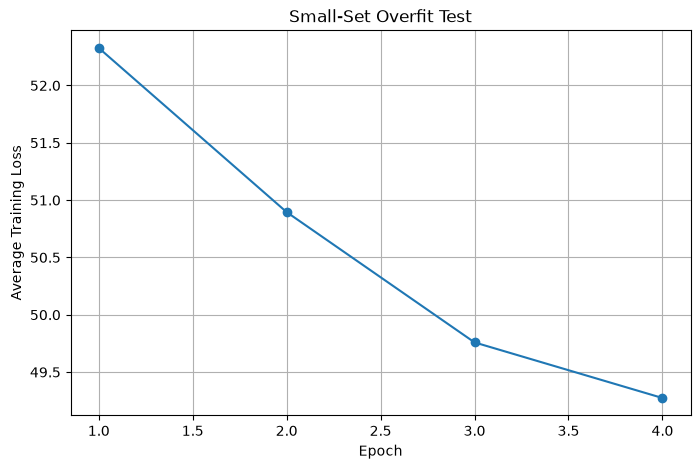

In [47]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    range(
        1,
        len(
            Training_History
        ) + 1
    ),
    Training_History,
    marker="o"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Average Training Loss"
)

plt.title(
    "Small-Set Overfit Test"
)

plt.grid(
    True
)

plt.show()

In [48]:
print(
    "Checkpoint Exists:",
    Small_Checkpoint_Path.exists()
)

print(
    "Checkpoint Size GB:",
    Small_Checkpoint_Path.stat().st_size
    /
    (
        1024 ** 3
    )
)

Checkpoint Exists: True
Checkpoint Size GB: 3.3877849439159036


In [49]:
Batch_Size = 1
Gradient_Accumulation_Steps = 8

Number_Of_Epochs = 5

Backbone_Learning_Rate = 1e-5
Head_Learning_Rate = 1e-4

Weight_Decay = 0.01
Gradient_Clip_Norm = 1.0

Checkpoint_Every = 250

In [50]:
EF_Mean = Train_Data["EF"].mean()
EF_Std = Train_Data["EF"].std()

In [52]:
EF_Mean = float(
    Train_Data["EF"].mean()
)

EF_Std = float(
    Train_Data["EF"].std()
)

print(
    "Train EF Mean:",
    EF_Mean
)

print(
    "Train EF Std:",
    EF_Std
)

Train EF Mean: 55.77764325112096
Train EF Std: 12.407189604685405


In [53]:
class EchoNetDataset(
    Dataset
):

    def __init__(
        self,
        DataFrame,
        Videos_Dir,
        EF_Mean,
        EF_Std,
        Number_Of_Frames=16,
        Image_Size=224
    ):

        self.DataFrame = (
            DataFrame
            .reset_index(drop=True)
        )

        self.Videos_Dir = Path(
            Videos_Dir
        )

        self.EF_Mean = float(
            EF_Mean
        )

        self.EF_Std = float(
            EF_Std
        )

        self.Number_Of_Frames = (
            Number_Of_Frames
        )

        self.Image_Size = (
            Image_Size
        )


    def __len__(
        self
    ):

        return len(
            self.DataFrame
        )


    def __getitem__(
        self,
        Index
    ):

        Row = self.DataFrame.iloc[
            Index
        ]

        Video_Name = str(
            Row["FileName"]
        )

        EF = float(
            Row["EF"]
        )


        EF_Normalized = (
            EF - self.EF_Mean
        ) / self.EF_Std


        Video_Path = (
            self.Videos_Dir
            /
            f"{Video_Name}.avi"
        )


        Video_Tensor, Frame_Indices = (
            Load_And_Preprocess_Video(
                Video_Path=Video_Path,
                Number_Of_Frames=
                    self.Number_Of_Frames,
                Image_Size=
                    self.Image_Size
            )
        )


        return {
            "video":
                Video_Tensor,

            "ef":
                torch.tensor(
                    EF,
                    dtype=torch.float32
                ),

            "ef_normalized":
                torch.tensor(
                    EF_Normalized,
                    dtype=torch.float32
                ),

            "video_name":
                Video_Name,

            "frame_indices":
                torch.as_tensor(
                    Frame_Indices,
                    dtype=torch.long
                )
        }

In [59]:
Train_Dataset = EchoNetDataset(
    DataFrame=Train_Data,
    Videos_Dir=Videos_Dir,
    EF_Mean=EF_Mean,
    EF_Std=EF_Std,
    Number_Of_Frames=Number_Of_Frames,
    Image_Size=Image_Size
)

Val_Dataset = EchoNetDataset(
    DataFrame=Val_Data,
    Videos_Dir=Videos_Dir,
    EF_Mean=EF_Mean,
    EF_Std=EF_Std,
    Number_Of_Frames=Number_Of_Frames,
    Image_Size=Image_Size
)

Test_Dataset = EchoNetDataset(
    DataFrame=Test_Data,
    Videos_Dir=Videos_Dir,
    EF_Mean=EF_Mean,
    EF_Std=EF_Std,
    Number_Of_Frames=Number_Of_Frames,
    Image_Size=Image_Size
)

In [61]:
Train_Loader = DataLoader(
    Train_Dataset,
    batch_size=Batch_Size,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

Val_Loader = DataLoader(
    Val_Dataset,
    batch_size=Batch_Size,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

Test_Loader = DataLoader(
    Test_Dataset,
    batch_size=Batch_Size,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

In [62]:
Batch = next(
    iter(
        Train_Loader
    )
)

print(
    Batch.keys()
)

dict_keys(['video', 'ef', 'ef_normalized', 'video_name', 'frame_indices'])


In [63]:
EF_Targets = (
    Batch[
        "ef_normalized"
    ]
    .to(
        Device
    )
)

print(
    "Normalized Targets:",
    EF_Targets
)

print(
    "Real EF:",
    Batch["ef"]
)

Normalized Targets: tensor([-1.1506], device='cuda:0')
Real EF: tensor([41.5016])
